Способы повышения обобщающей способности

Недообучение и переобучение моделей
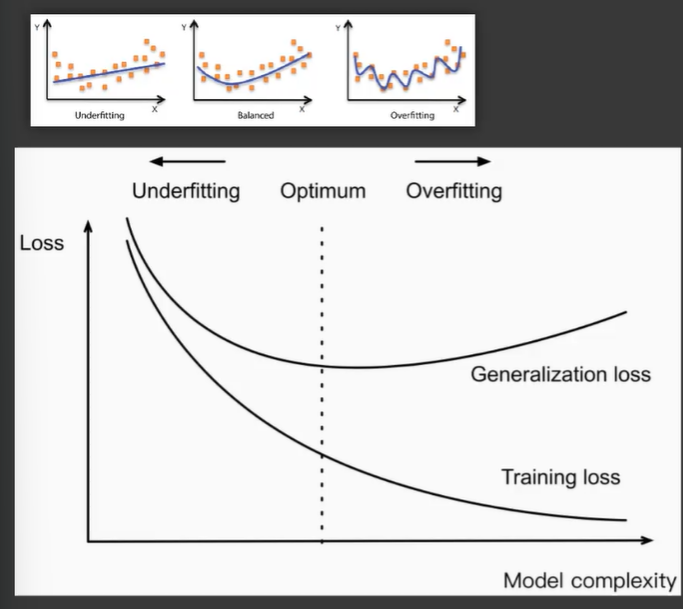

Generalization loss - ошибка обобщающей способности (не может работать с новыми данными)

In [11]:
import torch
from torch import nn
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader
from torchvision import transforms

In [12]:
train_dataset = MNIST(root='/simpleNN', train=True, download=True, transform=transforms.ToTensor())
valid_dataset = MNIST(root='/simpleNN', train=False, download=True, transform=transforms.ToTensor())

In [13]:
torch.manual_seed(42)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=32)
# DataLoader нужен для работы непосредственно с итератором, чтоб датасет
# не сразу загружался (дешевле)
# с MNIST будет загружаться 16 изображений и 16 метод

In [14]:
# torch это фреймворк, а не библиотека -> передаем код в фреймворк

class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(28 * 28 * 1, 64)
        # 28 * 28 * 1 - само изображение 64 - число нейронов (должно равняться пикселям)
        # 64 вышло, 64 вошло
        self.layer2 = nn.Linear(64, 32)
        self.layer3 = nn.Linear(32, 10)
        # в последнем нет произвольных чисел (является головой классификатора)
        self.activation = nn.ReLU()
        # SoftMax уже здесь есть
        self.flatten = nn.Flatten()

# прямой проход по сетке
    def forward(self, x):
        x = self.activation(self.layer1(self.flatten(x)))
        # читаем справа на лево)
        x = self.activation(self.layer2(x))
        x = self.layer3(x)
        # не пихаем сюда RELU и Сигмоиду
        return x

In [15]:
model = MLP()

In [16]:
# агностика - фрагмент кода, отслеживающий какое устройство нам доступно
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [17]:
model.to(device)

MLP(
  (layer1): Linear(in_features=784, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=32, bias=True)
  (layer3): Linear(in_features=32, out_features=10, bias=True)
  (activation): ReLU()
  (flatten): Flatten(start_dim=1, end_dim=-1)
)

In [18]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [19]:
import numpy as np


EPOCHS = 20

for epoch in range(EPOCHS):
    model.train()
    train_loss = []
    valid_loss = []
    print(f'Starting epoch {epoch + 1}')
    for data, targets in train_loader:
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad() # необходимо чтоб не использовались сразу все градиенты
        outputs = model(data)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())

    model.eval()
    # переводим в режим оценки, вычисление менее затратны, нет градиентов
    with torch.inference_mode():
        for data, targets in valid_loader:
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            loss = criterion(outputs, targets)
            # нет других, так как нет градиента
            valid_loss.append(loss.item())
            print(f'Epoch {epoch + 1} train loss: {np.mean(train_loss)} validation loss: {np.mean(valid_loss)}')

Starting epoch 1
Epoch 1 train loss: 0.719045270054539 validation loss: 0.2742918133735657
Epoch 1 train loss: 0.719045270054539 validation loss: 0.3305512070655823
Epoch 1 train loss: 0.719045270054539 validation loss: 0.3172987600167592
Epoch 1 train loss: 0.719045270054539 validation loss: 0.3192969784140587
Epoch 1 train loss: 0.719045270054539 validation loss: 0.3061191558837891
Epoch 1 train loss: 0.719045270054539 validation loss: 0.2969454824924469
Epoch 1 train loss: 0.719045270054539 validation loss: 0.3005570002964565
Epoch 1 train loss: 0.719045270054539 validation loss: 0.3259926736354828
Epoch 1 train loss: 0.719045270054539 validation loss: 0.32047735651334125
Epoch 1 train loss: 0.719045270054539 validation loss: 0.325539767742157
Epoch 1 train loss: 0.719045270054539 validation loss: 0.3418961329893632
Epoch 1 train loss: 0.719045270054539 validation loss: 0.34548934797445935
Epoch 1 train loss: 0.719045270054539 validation loss: 0.335339938218777
Epoch 1 train loss: 0

In [20]:
def interference(model, loader):
    dataiter = iter(loader)
    data, targets = next(dataiter)
    data, targets = data.to(device), targets.to(device)
    outputs = model(data)
    outputs = torch.argmax(outputs, dim=1)
    return outputs, targets

In [22]:
outputs, targets = interference(model, valid_loader)
print(outputs)
print()
print(targets)

tensor([7, 2, 1, 0, 4, 1, 4, 9, 6, 9, 0, 6, 9, 0, 1, 5, 9, 7, 3, 4, 9, 6, 6, 5,
        4, 0, 7, 4, 0, 1, 3, 1], device='cuda:0')

tensor([7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5, 9, 7, 3, 4, 9, 6, 6, 5,
        4, 0, 7, 4, 0, 1, 3, 1], device='cuda:0')


L1, L2 регуляризация и ElaticNEt

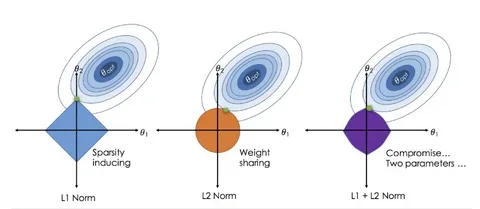

L1 регуляризация

In [23]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(28 * 28 * 1, 64)
        self.layer2 = nn.Linear(64, 32)
        self.layer3 = nn.Linear(32, 10)
        self.activation = nn.ReLU()
        self.flatten = nn.Flatten()

    def forward(self, x):
        x = self.activation(self.layer1(self.flatten(x)))
        x = self.activation(self.layer2(x))
        x = self.layer3(x)
        return x
    
    def compute_l1_loss(self, w):
        return torch.abs(w).sum()

In [24]:
model = MLP()
model.to(device)

MLP(
  (layer1): Linear(in_features=784, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=32, bias=True)
  (layer3): Linear(in_features=32, out_features=10, bias=True)
  (activation): ReLU()
  (flatten): Flatten(start_dim=1, end_dim=-1)
)

In [25]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [28]:
EPOCHS = 20

for epoch in range(EPOCHS):
    model.train()
    train_loss = []
    valid_loss = []
    print(f'Starting epoch {epoch + 1}')
    for data, targets in train_loader:
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        l1_weight = 1.0
        l1_parameters = []
        for parameter in model.parameters():
            l1_parameters.append(parameter.view(-1))
        l1 = l1_weight * model.compute_l1_loss(torch.cat(l1_parameters))
        loss += l1
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())

    model.eval()
    with torch.inference_mode():
        for data, targets in valid_loader:
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            loss = criterion(outputs, targets)
            l1_weight = 1.0
            l1_parameters = []
            for parameter in model.parameters():
                l1_parameters.append(parameter.view(-1))
            l1 = l1_weight * model.compute_l1_loss(torch.cat(l1_parameters))
            loss += l1
            valid_loss.append(loss.item())
            print(f'Epoch {epoch + 1} train loss: {np.mean(train_loss)} validation loss: {np.mean(valid_loss)}')

Starting epoch 1
Epoch 1 train loss: 136.7071592151006 validation loss: 3.192643404006958
Epoch 1 train loss: 136.7071592151006 validation loss: 3.1926480531692505
Epoch 1 train loss: 136.7071592151006 validation loss: 3.192647139231364
Epoch 1 train loss: 136.7071592151006 validation loss: 3.1926467418670654
Epoch 1 train loss: 136.7071592151006 validation loss: 3.1926470756530763
Epoch 1 train loss: 136.7071592151006 validation loss: 3.192647695541382
Epoch 1 train loss: 136.7071592151006 validation loss: 3.192648036139352
Epoch 1 train loss: 136.7071592151006 validation loss: 3.192648321390152
Epoch 1 train loss: 136.7071592151006 validation loss: 3.192648066414727
Epoch 1 train loss: 136.7071592151006 validation loss: 3.1926478147506714
Epoch 1 train loss: 136.7071592151006 validation loss: 3.19264817237854
Epoch 1 train loss: 136.7071592151006 validation loss: 3.1926483313242593
Epoch 1 train loss: 136.7071592151006 validation loss: 3.192648484156682
Epoch 1 train loss: 136.707159

KeyboardInterrupt: 

Тут прям очень плохо

Для малых нейронных сетей это не очень необходимо

Методы регуляризации обычно предназначены для больших НС

In [30]:
outputs, targets = interference(model, valid_loader)
print(outputs)
print()
print(targets)

tensor([7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
        7, 7, 7, 7, 7, 7, 7, 7], device='cuda:0')

tensor([7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5, 9, 7, 3, 4, 9, 6, 6, 5,
        4, 0, 7, 4, 0, 1, 3, 1], device='cuda:0')


L2 регуляризация

In [38]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(28 * 28 * 1, 64)
        self.layer2 = nn.Linear(64, 32)
        self.layer3 = nn.Linear(32, 10)
        self.activation = nn.ReLU()
        self.flatten = nn.Flatten()

    def forward(self, x):
        x = self.activation(self.layer1(self.flatten(x)))
        x = self.activation(self.layer2(x))
        x = self.layer3(x)
        return x
    
    def compute_l2_loss(self, w):
        return torch.square(w).sum()

In [42]:
model = MLP()
model.to(device)

MLP(
  (layer1): Linear(in_features=784, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=32, bias=True)
  (layer3): Linear(in_features=32, out_features=10, bias=True)
  (activation): ReLU()
  (flatten): Flatten(start_dim=1, end_dim=-1)
)

In [43]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=.1)
# weight_decay как раз трактуется почти как L2 регуляризация, встроена (поэтому чаще встречатеся)

L1 - зануляет параметры
L2 - постепенно убавляет параметры

In [44]:
EPOCHS = 20

for epoch in range(EPOCHS):
    model.train()
    train_loss = []
    valid_loss = []
    print(f'Starting epoch {epoch + 1}')
    for data, targets in train_loader:
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        # l2_weight = 1.0
        # l2_parameters = []
        # for parameter in model.parameters():
        #     l2_parameters.append(parameter.view(-1))
        # l2 = l2_weight * model.compute_l2_loss(torch.cat(l2_parameters))
        # loss += l2
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())

    model.eval()
    with torch.inference_mode():
        for data, targets in valid_loader:
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            loss = criterion(outputs, targets)
            # l2_weight = 1.0
            # l2_parameters = []
            # for parameter in model.parameters():
            #     l2_parameters.append(parameter.view(-1))
            # l2 = l2_weight * model.compute_l2_loss(torch.cat(l2_parameters))
            # loss += l2
            valid_loss.append(loss.item())
            print(f'Epoch {epoch + 1} train loss: {np.mean(train_loss)} validation loss: {np.mean(valid_loss)}')

Starting epoch 1
Epoch 1 train loss: 1.4182088572978973 validation loss: 1.010582447052002
Epoch 1 train loss: 1.4182088572978973 validation loss: 1.105380654335022
Epoch 1 train loss: 1.4182088572978973 validation loss: 1.076055606206258
Epoch 1 train loss: 1.4182088572978973 validation loss: 1.1053592562675476
Epoch 1 train loss: 1.4182088572978973 validation loss: 1.0934179306030274
Epoch 1 train loss: 1.4182088572978973 validation loss: 1.0978583097457886
Epoch 1 train loss: 1.4182088572978973 validation loss: 1.0934006316321236
Epoch 1 train loss: 1.4182088572978973 validation loss: 1.11255244910717
Epoch 1 train loss: 1.4182088572978973 validation loss: 1.1083966228697035
Epoch 1 train loss: 1.4182088572978973 validation loss: 1.111293876171112
Epoch 1 train loss: 1.4182088572978973 validation loss: 1.1160707798871128
Epoch 1 train loss: 1.4182088572978973 validation loss: 1.1176161170005798
Epoch 1 train loss: 1.4182088572978973 validation loss: 1.113228440284729
Epoch 1 train l

KeyboardInterrupt: 

L2 тоже не работает для маленьких НС

In [45]:
outputs, targets = interference(model, valid_loader)
print(outputs)
print()
print(targets)

tensor([7, 2, 1, 0, 4, 1, 9, 9, 6, 9, 0, 6, 9, 0, 1, 3, 4, 7, 2, 4, 7, 6, 6, 0,
        4, 0, 7, 4, 0, 1, 3, 1], device='cuda:0')

tensor([7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5, 9, 7, 3, 4, 9, 6, 6, 5,
        4, 0, 7, 4, 0, 1, 3, 1], device='cuda:0')


ElasticNet

In [47]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(28 * 28 * 1, 64)
        self.layer2 = nn.Linear(64, 32)
        self.layer3 = nn.Linear(32, 10)
        self.activation = nn.ReLU()
        self.flatten = nn.Flatten()

    def forward(self, x):
        x = self.activation(self.layer1(self.flatten(x)))
        x = self.activation(self.layer2(x))
        x = self.layer3(x)
        return x
    
    def compute_l1_loss(self, w):
        return torch.abs(w).sum()
    
    def compute_l2_loss(self, w):
        return torch.square(w).sum()

In [48]:
model = MLP()
model.to(device)


MLP(
  (layer1): Linear(in_features=784, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=32, bias=True)
  (layer3): Linear(in_features=32, out_features=10, bias=True)
  (activation): ReLU()
  (flatten): Flatten(start_dim=1, end_dim=-1)
)

In [49]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [50]:
EPOCHS = 20

for epoch in range(EPOCHS):
    model.train()
    train_loss = []
    valid_loss = []
    print(f'Starting epoch {epoch + 1}')
    for data, targets in train_loader:
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        l1_weight = 0.3
        l2_weight = 0.7
        parameters = []
        for parameter in model.parameters():
            parameters.append(parameter.view(-1))
        l1 = l1_weight * model.compute_l1_loss(torch.cat(parameters))
        l2 = l2_weight * model.compute_l2_loss(torch.cat(parameters))
        loss += l1
        loss += l2
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())

    model.eval()
    with torch.inference_mode():
        for data, targets in valid_loader:
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            loss = criterion(outputs, targets)
            l1_weight = 0.3
            l2_weight = 0.7
            parameters = []
            for parameter in model.parameters():
                parameters.append(parameter.view(-1))
            l1 = l1_weight * model.compute_l1_loss(torch.cat(parameters))
            l2 = l2_weight * model.compute_l2_loss(torch.cat(parameters))
            loss += l1
            loss += l2
            valid_loss.append(loss.item())
            print(f'Epoch {epoch + 1} train loss: {np.mean(train_loss)} validation loss: {np.mean(valid_loss)}')

Starting epoch 1
Epoch 1 train loss: 18.50196517798106 validation loss: 2.4807140827178955
Epoch 1 train loss: 18.50196517798106 validation loss: 2.48071026802063
Epoch 1 train loss: 18.50196517798106 validation loss: 2.480711062749227
Epoch 1 train loss: 18.50196517798106 validation loss: 2.48071026802063
Epoch 1 train loss: 18.50196517798106 validation loss: 2.4807106971740724
Epoch 1 train loss: 18.50196517798106 validation loss: 2.4807099103927612
Epoch 1 train loss: 18.50196517798106 validation loss: 2.480709893362863
Epoch 1 train loss: 18.50196517798106 validation loss: 2.480709046125412
Epoch 1 train loss: 18.50196517798106 validation loss: 2.4807086255815296
Epoch 1 train loss: 18.50196517798106 validation loss: 2.4807088375091553
Epoch 1 train loss: 18.50196517798106 validation loss: 2.4807089242068203
Epoch 1 train loss: 18.50196517798106 validation loss: 2.4807090957959494
Epoch 1 train loss: 18.50196517798106 validation loss: 2.4807088558490458
Epoch 1 train loss: 18.50196

KeyboardInterrupt: 

<h2>Dropout и BatchNorm

<h3>Dropout

Отключает нейроны с определённой вероятностью p

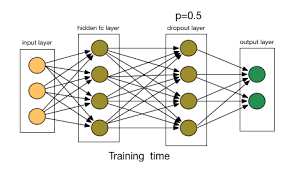

In [51]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(28 * 28 * 1, 64)
        self.layer2 = nn.Linear(64, 32)
        self.layer3 = nn.Linear(32, 10)
        self.activation = nn.ReLU()
        self.flatten = nn.Flatten()
        self.dropout = nn.Dropout(p=0.5)
    
    def forward(self, x):
        x = self.activation(self.layer1(self.flatten(x)))
        x = self.dropout(self.activation(self.layer2(x)))
        x = self.layer3(x)
        return x

In [52]:
model = MLP()
model.to(device)

MLP(
  (layer1): Linear(in_features=784, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=32, bias=True)
  (layer3): Linear(in_features=32, out_features=10, bias=True)
  (activation): ReLU()
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (dropout): Dropout(p=0.5, inplace=False)
)

In [54]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [55]:
EPOCHS = 20

for epoch in range(EPOCHS):
    model.train()
    train_loss = []
    valid_loss = []
    print(f'Starting epoch {epoch + 1}')
    for data, targets in train_loader:
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())

    model.eval()
    with torch.inference_mode():
        for data, targets in valid_loader:
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            loss = criterion(outputs, targets)
            valid_loss.append(loss.item())
            print(f'Epoch {epoch + 1} train loss: {np.mean(train_loss)} validation loss: {np.mean(valid_loss)}')

Starting epoch 1
Epoch 1 train loss: 1.1079260181585948 validation loss: 0.3703305721282959
Epoch 1 train loss: 1.1079260181585948 validation loss: 0.47033873200416565
Epoch 1 train loss: 1.1079260181585948 validation loss: 0.43794117371241253
Epoch 1 train loss: 1.1079260181585948 validation loss: 0.46659059822559357
Epoch 1 train loss: 1.1079260181585948 validation loss: 0.44409520626068116
Epoch 1 train loss: 1.1079260181585948 validation loss: 0.44176284472147626
Epoch 1 train loss: 1.1079260181585948 validation loss: 0.4420569198472159
Epoch 1 train loss: 1.1079260181585948 validation loss: 0.46700582653284073
Epoch 1 train loss: 1.1079260181585948 validation loss: 0.46156694491704303
Epoch 1 train loss: 1.1079260181585948 validation loss: 0.4710732281208038
Epoch 1 train loss: 1.1079260181585948 validation loss: 0.4837155179543929
Epoch 1 train loss: 1.1079260181585948 validation loss: 0.48997988800207776
Epoch 1 train loss: 1.1079260181585948 validation loss: 0.48084521752137405

KeyboardInterrupt: 

<h3>BatchNorm

<text>Суть данного метода заключается в том, что некоторым слоям нейронной сети на вход подаются данные, предварительно обработанные (нормализуем значения в Batch) и имеющие нулевое математическое ожидание и единичную дисперсию</text>

<span style="color:red">Предназначался для затухающих и взрывающихся градиентов</span>

<span style="color:blue">Главный вопрос: ставить BatchNorm до или после активации

In [56]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(28 * 28 * 1, 64)
        self.layer2 = nn.Linear(64, 32)
        self.bn = nn.BatchNorm1d(32)
        # Так как работает с вектором -> 1d
        self.layer3 = nn.Linear(32, 10)
        self.activation = nn.ReLU()
        self.flatten = nn.Flatten()

    def forward(self, x):
        x = self.activation(self.layer1(self.flatten(x)))
        x = self.bn(self.activation(self.layer2(x)))
        x = self.layer3(x)
        return x

In [57]:
model = MLP()
model.to(device)

MLP(
  (layer1): Linear(in_features=784, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=32, bias=True)
  (bn): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (layer3): Linear(in_features=32, out_features=10, bias=True)
  (activation): ReLU()
  (flatten): Flatten(start_dim=1, end_dim=-1)
)

In [59]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [60]:
EPOCHS = 20

for epoch in range(EPOCHS):
    model.train()
    train_loss = []
    valid_loss = []
    print(f'Starting epoch {epoch + 1}')
    for data, targets in train_loader:
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())

    model.eval()
    with torch.inference_mode():
        for data, targets in valid_loader:
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            loss = criterion(outputs, targets)
            valid_loss.append(loss.item())
            print(f'Epoch {epoch + 1} train loss: {np.mean(train_loss)} validation loss: {np.mean(valid_loss)}')

Starting epoch 1
Epoch 1 train loss: 0.6190361385265987 validation loss: 0.15819795429706573
Epoch 1 train loss: 0.6190361385265987 validation loss: 0.15986014902591705
Epoch 1 train loss: 0.6190361385265987 validation loss: 0.14489233245452246
Epoch 1 train loss: 0.6190361385265987 validation loss: 0.16614493541419506
Epoch 1 train loss: 0.6190361385265987 validation loss: 0.19306270331144332
Epoch 1 train loss: 0.6190361385265987 validation loss: 0.1767343965669473
Epoch 1 train loss: 0.6190361385265987 validation loss: 0.1825297549366951
Epoch 1 train loss: 0.6190361385265987 validation loss: 0.19766161497682333
Epoch 1 train loss: 0.6190361385265987 validation loss: 0.19484950022564995
Epoch 1 train loss: 0.6190361385265987 validation loss: 0.19784763529896737
Epoch 1 train loss: 0.6190361385265987 validation loss: 0.20999723740599371
Epoch 1 train loss: 0.6190361385265987 validation loss: 0.21676723721126714
Epoch 1 train loss: 0.6190361385265987 validation loss: 0.212171263992786

<center>Практическое задание</center>

1. Написать архитектуру MLP на более 5 слоёв и обучить модель на наборе данных Fashin MNIST (есть и в PyTorch)
2. Перепробовать различные методы регуляризации из пройденных на семинаре и отобрать наилучшую комбинацию в вашем случае